# Breast Cancer Diagnosis: Wisconsin Diagnostic Breast Cancer (WDBC)

Binary classification (benign vs malignant) from 30 numeric features computed from digitized images of fine-needle-aspirate (FNA) cell nuclei.

**Notebook outline**
1. EDA and preprocessing
2. Baselines: Logistic Regression and KNN, with stratified k-fold CV
3. **Tuned model comparison**: 6 model families (results generated by `src/train.py`)
4. Final evaluation of the selected model, interpretation and threshold analysis
5. Saved model and example prediction

> Run `python src/train.py` first to (re)generate the models and reports used in sections 3-5.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/wdbc.data", header=None)
print(df.shape)
df.head()

(569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
columns = [
    "id", "diagnosis",

    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",

    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",

    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

df.columns = columns

In [4]:
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [5]:
print(df["diagnosis"].value_counts())
print("---------------------------------------")
print(df["diagnosis"].value_counts(normalize=True))

diagnosis
B    357
M    212
Name: count, dtype: int64
---------------------------------------
diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64


In [6]:
print(df.isnull().sum().sum())

0


In [7]:
print(df.dtypes)

id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave_points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave_points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

## Exploratory Data Analysis

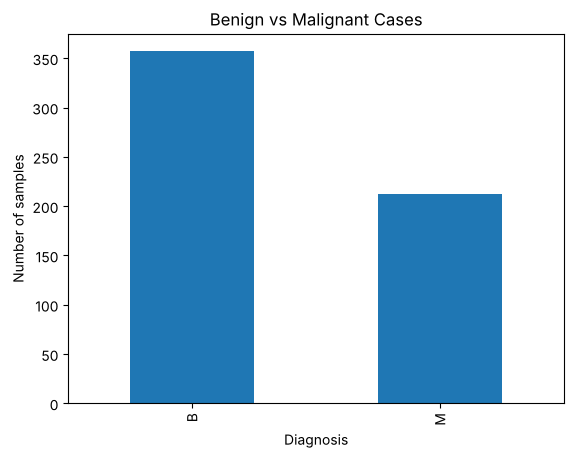

In [8]:
df["diagnosis"].value_counts().plot(kind="bar")

plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.title("Benign vs Malignant Cases")
plt.show()

In [9]:
df = df.drop(columns = ['id'])
print(df.describe())

       radius_mean  texture_mean  perimeter_mean    area_mean  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.000000   
25%      

we notice above that the feature such as area_mean have values in hundreds, whereas feature like smoothness_mean have values around 0.1. Thats one reason we need scaling


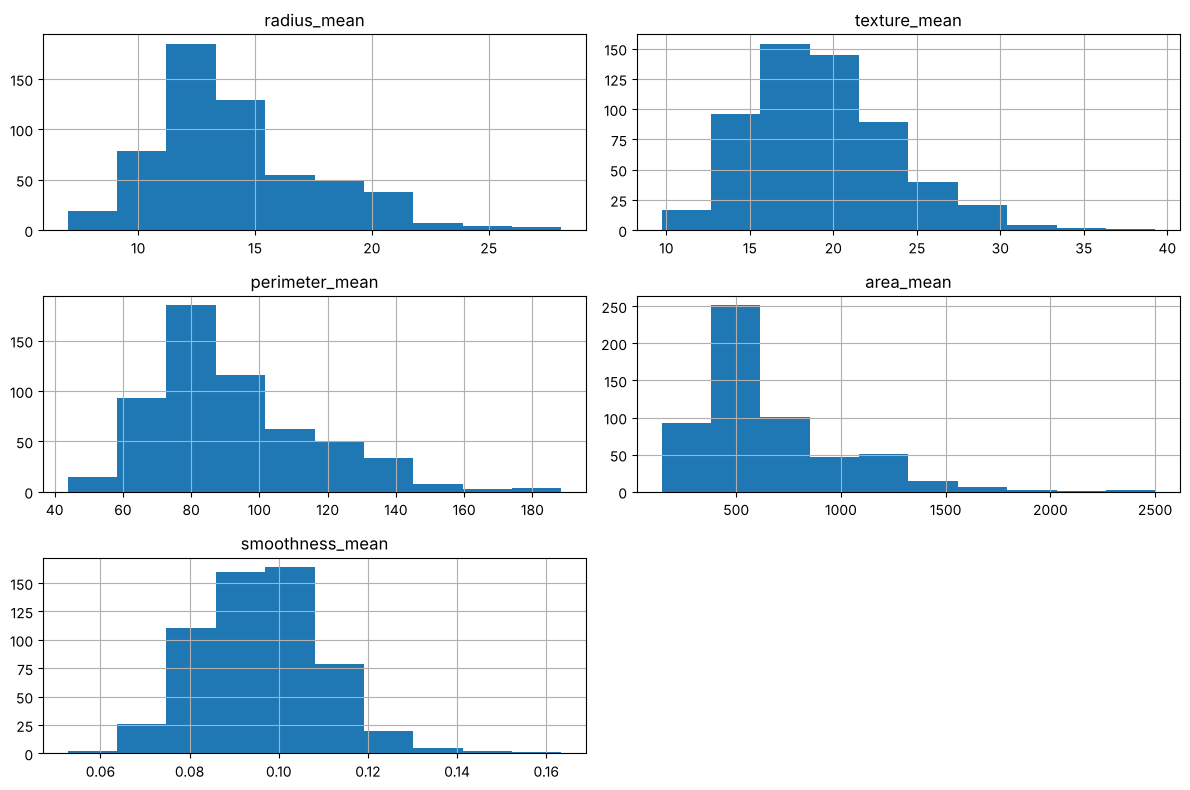

In [10]:
features = [
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean",
    "smoothness_mean"
]

df[features].hist(figsize=(12, 8))

plt.tight_layout()
plt.show()

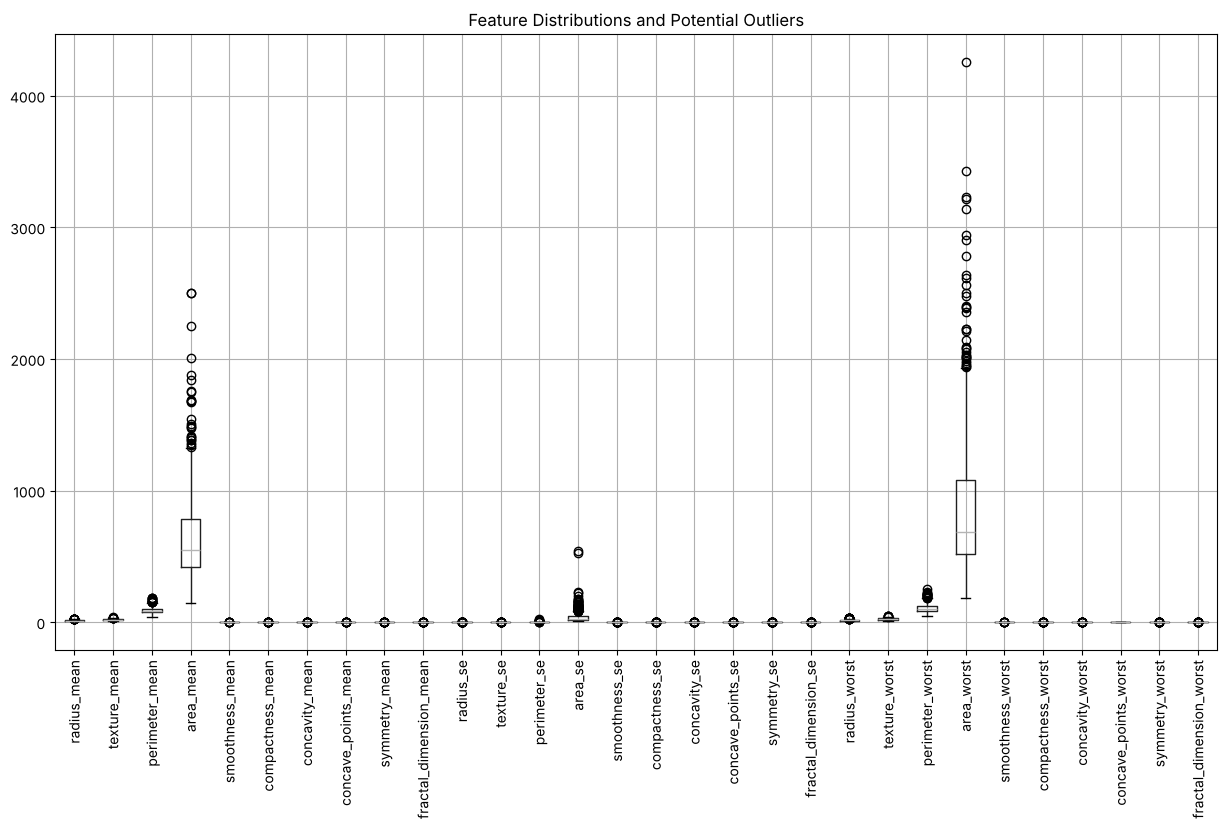

In [11]:
plt.figure(figsize=(15, 8))

df.drop(columns=["diagnosis"]).boxplot()

plt.xticks(rotation=90)
plt.title("Feature Distributions and Potential Outliers")
plt.show()

these outliers might not be errornous, as we are dealing here with Different breast-cell samples having different nuclear sizes and shapes. Those large values might actually contain useful information for distinguishing benign and malignant cases.

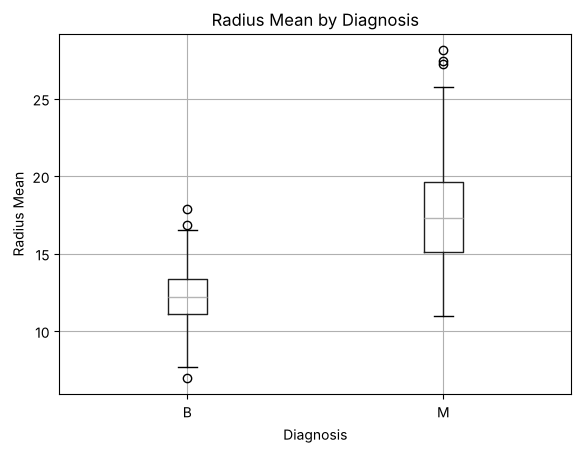

In [12]:
df.boxplot(
    column="radius_mean",
    by="diagnosis"
)

plt.title("Radius Mean by Diagnosis")
plt.suptitle("")
plt.xlabel("Diagnosis")
plt.ylabel("Radius Mean")
plt.show()

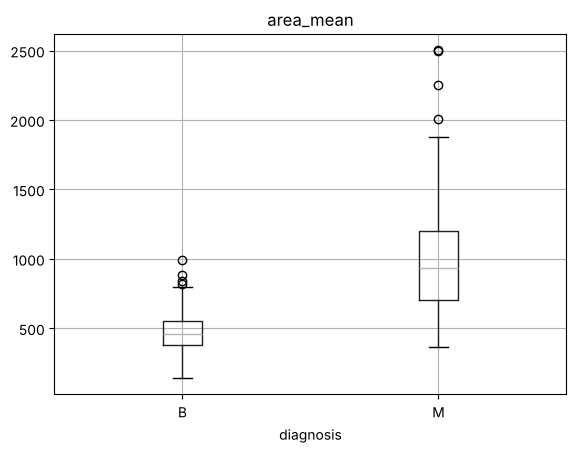

In [13]:
df.boxplot(column="area_mean", by="diagnosis")
plt.suptitle("")
plt.show()

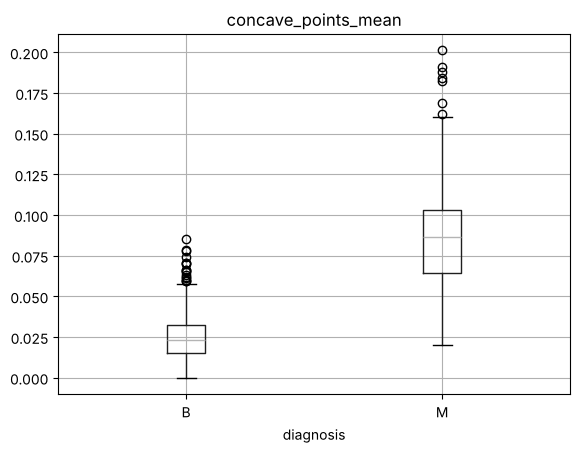

In [14]:
df.boxplot(column="concave_points_mean", by="diagnosis")
plt.suptitle("")
plt.show()

In [15]:
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


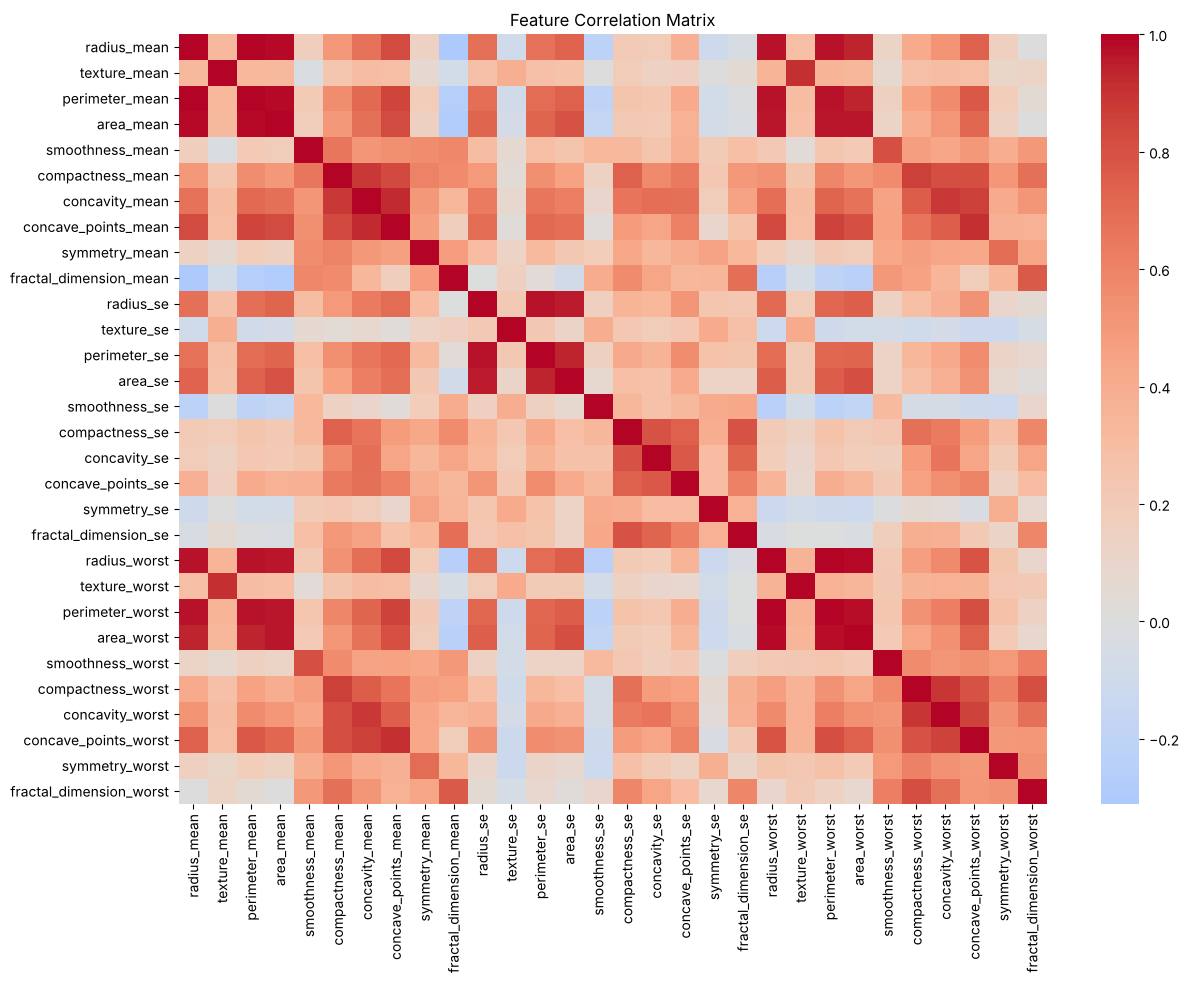

In [16]:
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    df.drop(columns=["diagnosis"]).corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.show()

In [17]:
df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


## Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
X_train

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
10,16.02,23.24,102.70,797.8,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,...,19.19,33.88,123.80,1150.0,0.11810,0.15510,0.14590,0.09975,0.2948,0.08452
170,12.32,12.39,78.85,464.1,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,...,13.50,15.64,86.97,549.1,0.13850,0.12660,0.12420,0.09391,0.2827,0.06771
407,12.85,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,...,14.40,27.01,91.63,645.8,0.09402,0.19360,0.18380,0.05601,0.2488,0.08151
430,14.90,22.53,102.10,685.0,0.09947,0.22250,0.27330,0.09711,0.2041,0.06898,...,16.35,27.57,125.40,832.7,0.14190,0.70900,0.90190,0.24750,0.2866,0.11550
27,18.61,20.25,122.10,1094.0,0.09440,0.10660,0.14900,0.07731,0.1697,0.05699,...,21.31,27.26,139.90,1403.0,0.13380,0.21170,0.34460,0.14900,0.2341,0.07421
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,13.03,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.02923,0.1467,0.05863,...,13.30,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169
415,11.89,21.17,76.39,433.8,0.09773,0.08120,0.02555,0.02179,0.2019,0.06290,...,13.05,27.21,85.09,522.9,0.14260,0.21870,0.11640,0.08263,0.3075,0.07351
458,13.00,25.13,82.61,520.2,0.08369,0.05073,0.01206,0.01762,0.1667,0.05449,...,14.34,31.88,91.06,628.5,0.12180,0.10930,0.04462,0.05921,0.2306,0.06291
476,14.20,20.53,92.41,618.4,0.08931,0.11080,0.05063,0.03058,0.1506,0.06009,...,16.45,27.26,112.10,828.5,0.11530,0.34290,0.25120,0.13390,0.2534,0.07858


In [21]:
X_test

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,12.82,15.97,83.74,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,25.58,27.00,165.30,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,16.97,19.14,113.10,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,16.33,30.86,109.50,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,15.05,41.61,96.69,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381,11.04,14.93,70.67,372.7,0.07987,0.07079,0.03546,0.02074,0.2003,0.06246,...,12.09,20.83,79.73,447.1,0.1095,0.1982,0.15530,0.06754,0.3202,0.07287
534,10.96,17.62,70.79,365.6,0.09687,0.09752,0.05263,0.02788,0.1619,0.06408,...,11.62,26.51,76.43,407.5,0.1428,0.2510,0.21230,0.09861,0.2289,0.08278
448,14.53,19.34,94.25,659.7,0.08388,0.07800,0.08817,0.02925,0.1473,0.05746,...,16.30,28.39,108.10,830.5,0.1089,0.2649,0.37790,0.09594,0.2471,0.07463
205,15.12,16.68,98.78,716.6,0.08876,0.09588,0.07550,0.04079,0.1594,0.05986,...,17.77,20.24,117.70,989.5,0.1491,0.3331,0.33270,0.12520,0.3415,0.09740


In [22]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

print(X_train_scaled.mean(axis=0)[:5])
print(X_train_scaled.std(axis=0)[:5])

(455, 30)
(114, 30)
[-1.73731603e-16  3.90408097e-16  4.70441756e-16 -1.17122429e-16
  7.24207019e-16]
[1. 1. 1. 1. 1.]


## Logistic Regression (baseline)

In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [24]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)

# KNN 'training' just stores the points
knn.fit(X_train_scaled, y_train)

# Predict and evaluate
predictions = knn.predict(X_test_scaled)
print(f"Model Accuracy: {accuracy_score(y_test, predictions):.2%}")

Model Accuracy: 95.61%


In [25]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:20])

[0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]


In [26]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(y_prob[:10])

[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [27]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9649122807017544


In [28]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



[[71  1]
 [ 3 39]]


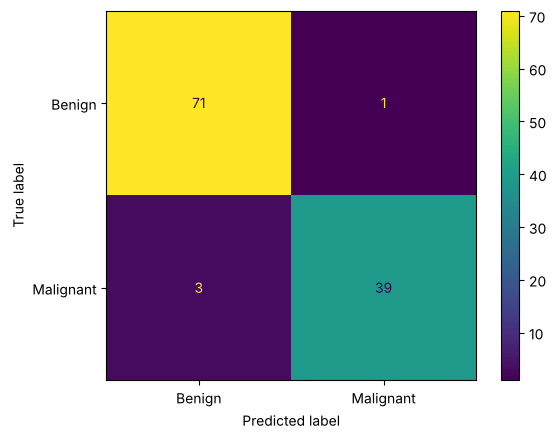

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
).plot()

plt.show()

In [30]:
y_prob

array([3.64568116e-04, 9.99999989e-01, 4.25679471e-02, 5.76187322e-01,
       5.09155489e-01, 6.16001620e-04, 7.61534086e-01, 1.01217174e-03,
       5.68725516e-04, 1.07675795e-02, 9.30905953e-01, 7.28319772e-05,
       9.99999899e-01, 4.39449272e-03, 7.75262630e-03, 1.70641370e-06,
       6.14294329e-02, 3.62811536e-04, 2.21762013e-01, 5.07279789e-05,
       1.26622816e-03, 4.30342121e-03, 9.99999581e-01, 9.98321524e-01,
       7.57606906e-01, 2.05880632e-04, 1.68680282e-04, 9.69171419e-01,
       9.96639529e-01, 9.99579644e-01, 9.99991854e-01, 2.37027672e-03,
       9.99964222e-01, 9.99954679e-01, 2.66371788e-04, 1.39030746e-02,
       2.02020415e-03, 3.20211147e-06, 9.90930715e-01, 9.31932725e-02,
       1.25745605e-04, 3.52528144e-04, 8.52325081e-01, 2.51409506e-03,
       1.08172442e-02, 9.54067888e-01, 7.56926419e-02, 9.98508631e-01,
       5.69898683e-05, 1.11541174e-03, 9.99999992e-01, 9.98457814e-01,
       7.12763094e-03, 1.05057651e-03, 1.21417298e-04, 9.88025845e-01,
      

In [31]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.996031746031746


## Stratified k-fold cross-validation

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Fold accuracies:", scores)
print("Mean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Fold accuracies: [0.97368421 0.94736842 0.96491228 0.99122807 0.99115044]
Mean accuracy: 0.9736686849868033
Standard deviation: 0.016627222216787987


In [33]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

# KNN pipeline
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_scores = cross_val_score(
    knn_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("KNN Fold accuracies:", knn_scores)
print("KNN Mean accuracy:", knn_scores.mean())
print("KNN Standard deviation:", knn_scores.std())

KNN Fold accuracies: [0.98245614 0.94736842 0.93859649 0.98245614 0.96460177]
KNN Mean accuracy: 0.9630957925787922
KNN Standard deviation: 0.01788563714959112


---

## 3. Tuned model comparison: ten classifiers

The baselines above use default hyperparameters. This section compares **ten tuned
classifier configurations** produced by `src/train.py`:

| # | Model | Scaled? | Family |
|---|-------|---------|--------|
| 1 | Logistic Regression | yes | linear |
| 2 | Linear Discriminant Analysis (LDA) | yes | linear |
| 3 | K-Nearest Neighbors | yes | instance-based |
| 4 | Decision Tree | no | tree |
| 5 | Random Forest | no | ensemble (bagging) |
| 6 | Gaussian Naive Bayes | no | probabilistic |
| 7 | SVM, linear kernel | yes | kernel |
| 8 | SVM, RBF kernel | yes | kernel |
| 9 | Neural network (MLPClassifier) | yes | neural network |
| 10 | Gradient Boosting | no | ensemble (boosting) |

**Protocol.** Every model is a scikit-learn `Pipeline`, so `StandardScaler` is re-fitted
inside each CV fold and never sees the validation rows — no leakage. Tree-based and
Naive Bayes models are left unscaled, since they are invariant to monotone rescaling.

* **Tuning:** `GridSearchCV`, `StratifiedKFold(5, shuffle=True, random_state=42)`,
  scored on ROC-AUC, **fitted on the training split only**.
* **Comparison:** the tuned configuration is then re-scored with
  `RepeatedStratifiedKFold(5 splits x 3 repeats, random_state=42)` — 15 folds,
  **identical for every model**, so differences can be compared fold by fold.
* **The held-out test set is not touched** during tuning or selection.

Malignant (**M = 1**) is the positive class throughout.

> Run `python src/train.py` then `python src/evaluate.py` from the `wdbc/` folder to
> regenerate everything loaded below.

In [ ]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

REPORTS = Path("../reports")
FIGURES = REPORTS / "figures"
MODELS = Path("../models")

comparison = pd.read_csv(REPORTS / "model_comparison.csv")
split_info = json.loads((REPORTS / "split_info.json").read_text())
selection = json.loads((REPORTS / "model_selection.json").read_text())

print(f"{split_info['n_samples']} samples, {split_info['n_features']} features")
print(f"missing values: {split_info['missing_values']}   duplicate rows: {split_info['duplicate_rows']}")
print(f"class balance : {split_info['class_counts']}  ({split_info['malignant_rate']:.1%} malignant)")
print(f"train / test  : {split_info['n_train']} / {split_info['n_test']}  "
      f"(test: {split_info['test_class_counts']})")
print(f"inner CV      : {split_info['inner_cv']}")
print(f"outer CV      : {split_info['outer_cv']}")

### 3.1 Consolidated comparison table

Cross-validated means (training split only) alongside the held-out test numbers.
The CV columns are what model selection is based on; the test columns are reported
once, at the end, and play no part in choosing anything.

In [ ]:
headline = comparison[[
    "model", "cv_accuracy_mean", "cv_precision_mean", "cv_recall_mean", "cv_f1_mean",
    "cv_roc_auc_mean", "cv_pr_auc_mean",
    "test_accuracy", "test_recall", "test_roc_auc",
]].copy()
headline.columns = ["Model", "CV Accuracy", "CV Precision", "CV Recall", "CV F1",
                    "CV ROC-AUC", "CV PR-AUC", "Test Accuracy", "Test Recall", "Test ROC-AUC"]
headline.round(4)

In [ ]:
# the same CV numbers with their fold-to-fold spread, plus specificity and balanced accuracy
spread = comparison[["model"]].copy()
for m in ["accuracy", "precision", "recall", "specificity", "f1",
          "roc_auc", "pr_auc", "balanced_accuracy"]:
    spread[m] = [f"{a:.4f} +/- {b:.4f}"
                 for a, b in zip(comparison[f"cv_{m}_mean"], comparison[f"cv_{m}_std"])]
spread.set_index("model")

In [ ]:
# hyperparameters chosen by grid search, and what each search cost
for _, r in comparison.iterrows():
    print(f"{r['model']:21s} {r['n_candidates']:3d} candidates  "
          f"{r['tune_seconds']:6.1f}s  ->  {r['best_params']}")

### 3.2 Visual comparison

Mean CV accuracy with error bars at +/- 1 SD across the 15 folds. Where the bars
overlap, the models are tied on this evidence.

In [ ]:
display(Image(FIGURES / "01_cv_accuracy_comparison.png"))

A single metric hides the trade-offs, so here are all eight at once. Read it by row:
LDA and KNN buy their high precision and specificity with noticeably lower **recall**,
which is the expensive error in this problem.

In [ ]:
display(Image(FIGURES / "05_metric_heatmap.png"))

### 3.3 Are the differences meaningful?

Because every model saw the **identical** 15 folds, the scores can be differenced
fold by fold. The table below reports the paired difference (selected model minus
each other model) with a 95% interval. An interval containing 0 means the data do
not demonstrate a difference.

The intervals are a rough guide only: repeated CV folds overlap heavily, so the
nominal 95% coverage is optimistic. Small gaps should be read as ties.

In [ ]:
paired = pd.read_csv(REPORTS / "cv_paired_vs_best.csv")
paired[paired["metric"] == "roc_auc"].round(4).set_index("model")[
    ["mean_diff", "ci_lo", "ci_hi", "ci_excludes_0", "conclusion"]]

In [ ]:
# how many models sit within one standard deviation of the leader's CV ROC-AUC?
top = comparison.iloc[0]
tied = comparison[comparison["cv_roc_auc_mean"] >= top["cv_roc_auc_mean"] - top["cv_roc_auc_std"]]
print(f"leader: {top['model']}  CV ROC-AUC {top['cv_roc_auc_mean']:.4f} "
      f"+/- {top['cv_roc_auc_std']:.4f}")
print(f"within 1 SD of it: {len(tied)} of {len(comparison)} models")
print("  " + ", ".join(tied["model"]))

### 3.4 Computational cost

Accuracy is not the only axis. The linear models fit in milliseconds; the ensembles
and the MLP cost one to three orders of magnitude more, for no measurable gain here.

In [ ]:
display(Image(FIGURES / "08_training_time.png"))

---

## 4. Model selection

Selection uses **cross-validation results only**, and deliberately **not accuracy alone**.
The rule is the lowest weighted average rank over five criteria:

* CV ROC-AUC (weight 2) — threshold-free ranking quality
* CV recall on malignant cases (weight 2) — a missed malignancy is the costly error
* CV F1, CV PR-AUC, CV balanced accuracy (weight 1 each)

ROC-AUC and recall are doubled because the cost of the two error types is not symmetric.
Accuracy is reported but never used as a tie-breaker: at 37% malignant prevalence,
a model can look accurate while missing malignancies.

In [ ]:
print("selection rule:", selection["selection_rule"], "\n")
ranking = pd.DataFrame(selection["ranking"]).round(4)
display(ranking)
best_name = selection["selected_model"]
print(f"\nselected: {best_name}   {selection['best_params']}")

### 4.1 Evaluation on the untouched test set

Now, and only now, the held-out 114 cases are used.

A caution on reading these numbers: the test set holds **42 malignant** cases, so one
extra miss moves recall by 2.4 points. Gaps of one or two cases between models are
noise, not evidence.

In [ ]:
test_cols = ["model", "test_accuracy", "test_precision", "test_recall",
             "test_specificity", "test_f1", "test_roc_auc", "test_pr_auc",
             "test_balanced_accuracy", "test_npv", "tn", "fp", "fn", "tp"]
comparison[test_cols].round(4).set_index("model")

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

import sys
sys.path.insert(0, "../src")
from train import load_data, split          # the single source of truth for the split

X, y = load_data()
X_train, X_test, y_train, y_test = split(X, y)

best = joblib.load(MODELS / "best_model.joblib")
print(best, "\n")
print(classification_report(y_test, best.predict(X_test),
                            target_names=["Benign", "Malignant"], digits=4))

In [ ]:
cm = confusion_matrix(y_test, best.predict(X_test))
print("confusion matrix (rows = true B/M, columns = predicted B/M)")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\nfalse negatives (missed malignancies): {fn}")
print(f"false positives (false alarms)       : {fp}")

In [ ]:
display(Image(FIGURES / "04_confusion_matrices.png"))

In [ ]:
display(Image(FIGURES / "02_roc_curves.png"))

In [ ]:
display(Image(FIGURES / "03_pr_curves.png"))

### 4.2 Why this model, and where it falls short

**Why it performs well.** The WDBC features were engineered for exactly this task, and
the classes are close to linearly separable in the 30-dimensional standardised space —
the dataset documentation notes the two classes are linearly separable using all 30
features. A regularised linear boundary is therefore already the right shape for the
problem. With 455 training rows and 30 correlated features, the L2 penalty also does
real work: it is the main defence against the collinearity among the radius / perimeter
/ area group.

**More complex is not better here.** On ROC-AUC the paired fold-wise intervals for LDA,
the MLP and the RBF SVM all include zero, so those three are statistically
indistinguishable from the selected model; the tree ensembles and KNN are measurably
behind. LDA ties on AUC but reaches it with markedly lower malignant recall (0.882 against
0.957), which is exactly why recall carries weight in the selection rule. Among a set of ties, the
cheapest and most interpretable model is the reasonable choice — it trains in about ten
milliseconds and its coefficients can be read directly.

**Limitations.**

* **One small dataset, one source.** 569 cases from a single institution, digitised with
  one imaging and segmentation pipeline. Nothing here speaks to how it transfers.
* **Features, not images.** The 30 inputs are the output of a hand-built nuclear
  segmentation step. A deployed system would have to reproduce that step, and its errors.
* **The test set is small.** 114 cases, 42 of them malignant. The test-set intervals
  around these point estimates are wide.
* **Correlated features make coefficients hard to read individually.** radius, perimeter
  and area are near-duplicates; the penalty spreads credit among them more or less
  arbitrarily, so coefficients should be read as *groups* of related measurements.
* **Probabilities are uncalibrated.** They are used below for thresholding, which only
  needs the ranking, but they should not be reported as literal risks.
* **No external validation**, no patient-level grouping, no prospective evaluation.

---

## 5. Interpretation: which measurements drive the prediction?

Two views. First the standardised logistic-regression coefficients — the sign says which
way a feature pushes, the magnitude how hard. Because many features are near-duplicates,
read these as *groups* (size, texture, concavity, symmetry) rather than as isolated effects.

In [ ]:
display(Image(FIGURES / "07_lr_coefficients.png"))

In [ ]:
coefs = pd.read_csv(REPORTS / "lr_coefficients.csv").set_index("feature")
coefs["abs"] = coefs["coefficient"].abs()
coefs.sort_values("abs", ascending=False).head(10)[["coefficient", "odds_ratio"]].round(4)

Second, the impurity-based importances of the tree ensembles. They agree on the broad
story — the "worst" (largest-three-nuclei) concavity and size measurements carry most of
the signal — which is reassuring, since the two model families arrive at it by completely
different routes.

In [ ]:
display(Image(FIGURES / "06_feature_importance.png"))

In [ ]:
imp = pd.read_csv(REPORTS / "feature_importance.csv").set_index("feature")
tree_cols = [c for c in imp.columns]
imp["mean_importance"] = imp[tree_cols].mean(axis=1)
imp.sort_values("mean_importance", ascending=False).head(12).round(4)

---

## 6. Decision threshold analysis

A false negative — a malignant case called benign — is far more costly here than a false
positive, which leads to a follow-up test. The default 0.5 cut-off optimises neither.

**The threshold is chosen from cross-validated predictions on the training split only**
(`cross_val_predict` over the 455 training rows). Picking it by looking at test-set
results would be tuning on the test set, which is exactly what the held-out split exists
to prevent. The rule: the highest threshold whose cross-validated recall still reaches
the 0.98 target — highest, because among the thresholds that meet the recall target it is
the one that gives away the least precision.

In [ ]:
thr_cv = pd.read_csv(REPORTS / "threshold_analysis.csv")
chosen = json.loads((REPORTS / "selected_threshold.json").read_text())

print(f"recommended threshold: {chosen['threshold']:.2f}  "
      f"(target CV recall >= {chosen['target_recall']})")
print(f"rule: {chosen['selection_rule']}\n")

view = thr_cv[thr_cv["threshold"].isin([0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70])]
view[["threshold", "recall", "precision", "specificity", "f1", "fn", "fp"]].round(4).set_index("threshold")

In [ ]:
display(Image(FIGURES / "09_threshold_tradeoff.png"))

In [ ]:
# what the move costs and buys, on the training-split CV predictions
a = chosen["training_cv_at_default_0.5"]
b = chosen["training_cv_at_threshold"]
print(f"threshold 0.50 -> recall {a['recall']:.4f}  precision {a['precision']:.4f}  "
      f"FN {int(a['fn'])}  FP {int(a['fp'])}")
print(f"threshold {chosen['threshold']:.2f} -> recall {b['recall']:.4f}  precision {b['precision']:.4f}  "
      f"FN {int(b['fn'])}  FP {int(b['fp'])}")
print(f"\n{int(a['fn'] - b['fn'])} fewer missed malignancies, "
      f"at the cost of {int(b['fp'] - a['fp'])} more false alarms (out of 455 training cases).")

In [ ]:
# the same sweep on the test set - REPORTING ONLY, it did not inform the choice above
thr_test = pd.read_csv(REPORTS / "threshold_analysis_test.csv")
thr_test[thr_test["threshold"].isin([0.20, 0.30, 0.50])][
    ["threshold", "recall", "precision", "specificity", "f1", "fn", "fp"]].round(4).set_index("threshold")

> **This is an educational classification experiment, not a clinically validated
> diagnostic system.** The threshold above is chosen against a recall target picked for
> illustration, not against measured clinical costs, and the model has had no external
> validation, no prospective evaluation and no regulatory assessment. Nothing in this
> notebook should be used to inform a diagnosis or a clinical decision.

---

## 7. Using the saved model

The saved object is a full `Pipeline` (scaler + classifier), so raw feature values can be
passed straight in — no manual scaling.

In [ ]:
sample = X_test.iloc[[0]]
p = best.predict_proba(sample)[0, 1]
truth = "Malignant" if y_test.iloc[0] else "Benign"
print(f"P(malignant) = {p:.4f}")
print(f"  at threshold 0.50 -> {'Malignant' if p >= 0.50 else 'Benign'}")
print(f"  at threshold {chosen['threshold']:.2f} -> {'Malignant' if p >= chosen['threshold'] else 'Benign'}")
print(f"  true label        -> {truth}")

---

## 8. Conclusions

**Selected model.** Logistic Regression (L2, `C=1`) on standardised features, chosen on
cross-validated ROC-AUC and malignant recall rather than accuracy.

**What the comparison showed.** On ROC-AUC, four of the ten models — the selected one,
LDA, the MLP and the RBF SVM — are statistically indistinguishable on 15 shared CV folds
(and six sit within one standard deviation of the leader).
The tree ensembles, KNN, Naive Bayes and especially the single Decision Tree sit
measurably behind. On a small, well-separated, near-linear dataset the simplest model
wins, and it does so while training two to three orders of magnitude faster. *More
complex did not mean better.*

**Threshold.** Lowering the cut-off from 0.50 to 0.20 — chosen on training-split CV
predictions alone — trades a handful of extra false alarms for a meaningful reduction in
missed malignancies, which is the right direction for a screening-style task.

**Methodology.** All preprocessing lives inside `Pipeline` objects, so the scaler is
re-fitted per fold and there is no train/test leakage. Hyperparameters were tuned on the
training split only; all ten models were compared on the same folds; the test set was
read once.

**Limitations.** One small single-source dataset, pre-extracted rather than raw-image
features, a 114-case test set, heavily correlated predictors, uncalibrated probabilities,
and no external validation. **An educational project, not a clinical tool.**

**Next steps.** Calibrate the probabilities (`CalibratedClassifierCV`), set the threshold
against real clinical costs instead of a chosen recall target, handle the collinearity
explicitly (feature grouping, elastic net or PCA), add nested CV so the selection step is
itself validated, and test on an independent cohort.